In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Partie A : Exploration et préparation

**Q1.** DataFrame

In [2]:
diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

print("Dimensions :", df.shape)
df.head()

Dimensions : (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


**Q2.** Statistiques descriptives

In [3]:
df.describe().round(3)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


**Q3.** Corrélation avec `target`

In [4]:
print(df.corr()['target'].drop('target').sort_values(ascending=False).round(3))

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


**Q4.** X, y et séparation

In [5]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, " Test :", X_test.shape)

Train : (353, 10)  Test : (89, 10)


## Partie B : Régression linéaire simple

**Q5.** Modèle avec `bmi` seule

In [6]:
modele_simple = LinearRegression().fit(X_train[['bmi']], y_train)

a, b = modele_simple.coef_[0], modele_simple.intercept_
print(f"coef_ = {a:.2f}   intercept_ = {b:.2f}")
print(f"Équation : target = {a:.2f} × bmi + {b:.2f}")

coef_ = 998.58   intercept_ = 152.00
Équation : target = 998.58 × bmi + 152.00


**Q6.** Métriques sur le test

In [7]:
y_pred_simple = modele_simple.predict(X_test[['bmi']])

mae_s = mean_absolute_error(y_test, y_pred_simple)
rmse_s = np.sqrt(mean_squared_error(y_test, y_pred_simple))
r2_s = r2_score(y_test, y_pred_simple)

print("MAE  :", round(mae_s, 2))
print("MSE  :", round(mean_squared_error(y_test, y_pred_simple), 2))
print("RMSE :", round(rmse_s, 2))
print("R²   :", round(r2_s, 3))

MAE  : 52.26
MSE  : 4061.83
RMSE : 63.73
R²   : 0.233


**Q7.** Nuage de points et droite

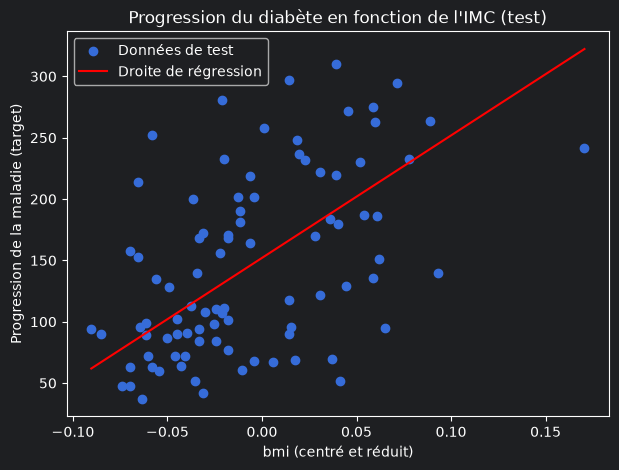

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test['bmi'], y_test, label="Données de test")

x_droite = pd.DataFrame({'bmi': np.linspace(X_test['bmi'].min(), X_test['bmi'].max(), 100)})
plt.plot(x_droite['bmi'], modele_simple.predict(x_droite), color='red', label="Droite de régression")

plt.title("Progression du diabète en fonction de l'IMC (test)")
plt.xlabel("bmi (centré et réduit)")
plt.ylabel("Progression de la maladie (target)")
plt.legend()
plt.show()

## Partie C : Régression linéaire multiple

**Q8.** Coefficients

In [9]:
modele_multi = LinearRegression().fit(X_train, y_train)

coefs = pd.DataFrame({'variable': X.columns, 'coefficient': modele_multi.coef_})
coefs.sort_values('coefficient', key=abs, ascending=False).reset_index(drop=True).round(1)

,variable,coefficient
0,s1,-931.5
1,s5,736.2
2,bmi,542.4
3,s2,518.1
4,bp,347.7
5,s4,275.3
6,sex,-242.0
7,s3,163.4
8,s6,48.7
9,age,37.9


**Q9.** Métriques et comparaison

In [10]:
y_pred_multi = modele_multi.predict(X_test)

mae_m = mean_absolute_error(y_test, y_pred_multi)
rmse_m = np.sqrt(mean_squared_error(y_test, y_pred_multi))
r2_m = r2_score(y_test, y_pred_multi)

print("MAE  :", round(mae_m, 2), "(simple :", round(mae_s, 2), ")")
print("MSE  :", round(mean_squared_error(y_test, y_pred_multi), 2))
print("RMSE :", round(rmse_m, 2), "(simple :", round(rmse_s, 2), ")")
print("R²   :", round(r2_m, 3), "(simple :", round(r2_s, 3), ")")

MAE  : 42.79 (simple : 52.26 )
MSE  : 2900.19
RMSE : 53.85 (simple : 63.73 )
R²   : 0.453 (simple : 0.233 )


**Q10.** R² ajusté

In [12]:
def r2_ajuste(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

n_test = len(y_test)
print("Simple   (p = 1)  :", round(r2_ajuste(r2_s, n_test, 1), 3))
print("Multiple (p = 10) :", round(r2_ajuste(r2_m, n_test, 10), 3))

Simple   (p = 1)  : 0.225
Multiple (p = 10) : 0.382


**Q11.** R² entraînement et test

In [13]:
print("R² entraînement :", round(r2_score(y_train, modele_multi.predict(X_train)), 3))
print("R² test         :", round(r2_m, 3))

R² entraînement : 0.528
R² test         : 0.453


## Partie D : Autres modèles

**Q12 et Q13.** Arbre, KNN, SVR et tableau comparatif

In [14]:
modeles = {
    'Régression linéaire multiple': modele_multi,
    'Arbre (max_depth=3)': DecisionTreeRegressor(max_depth=3, random_state=42),
    'KNN (k=5)': KNeighborsRegressor(n_neighbors=5),
    'SVR (rbf, C=100)': SVR(kernel='rbf', C=100),
}

preds = {}
lignes = []
for nom, modele in modeles.items():
    if nom != 'Régression linéaire multiple':
        modele.fit(X_train, y_train)
    preds[nom] = modele.predict(X_test)
    lignes.append({
        'Modèle': nom,
        'MAE': mean_absolute_error(y_test, preds[nom]),
        'RMSE': np.sqrt(mean_squared_error(y_test, preds[nom])),
        'R²': r2_score(y_test, preds[nom]),
    })

resultats = pd.DataFrame(lignes).set_index('Modèle').round(3)
display(resultats)
print("Meilleur selon la RMSE :", resultats['RMSE'].idxmin())
print("Meilleur selon le R²   :", resultats['R²'].idxmax())

,MAE,RMSE,R²
Modèle,,,
Régression linéaire multiple,42.794,53.853,0.453
Arbre (max_depth=3),48.097,59.605,0.329
KNN (k=5),42.771,54.946,0.430
"SVR (rbf, C=100)",39.385,51.018,0.509


Meilleur selon la RMSE : SVR (rbf, C=100)
Meilleur selon le R²   : SVR (rbf, C=100)


**Q14.** Valeurs réelles en fonction des valeurs prédites

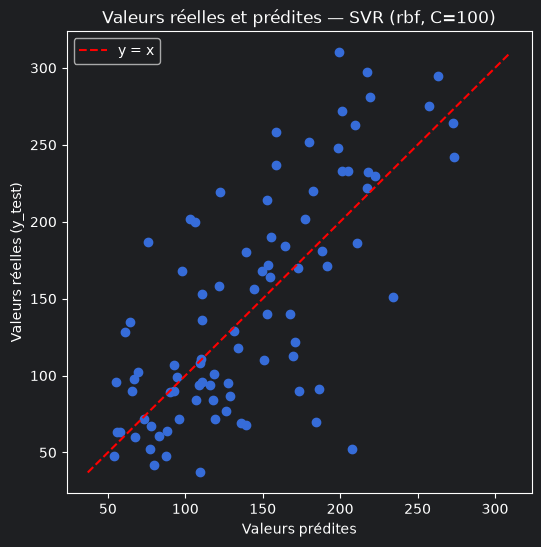

In [15]:
meilleur = resultats['RMSE'].idxmin()
pred_best = preds[meilleur]

plt.figure(figsize=(6, 6))
plt.scatter(pred_best, y_test)
mini, maxi = min(pred_best.min(), y_test.min()), max(pred_best.max(), y_test.max())
plt.plot([mini, maxi], [mini, maxi], 'r--', label="y = x")
plt.title(f"Valeurs réelles et prédites — {meilleur}")
plt.xlabel("Valeurs prédites")
plt.ylabel("Valeurs réelles (y_test)")
plt.legend()
plt.show()

Un point **loin de la droite** est une prédiction avec une grosse erreur.

**Q15.** Arbre de régression selon `max_depth`

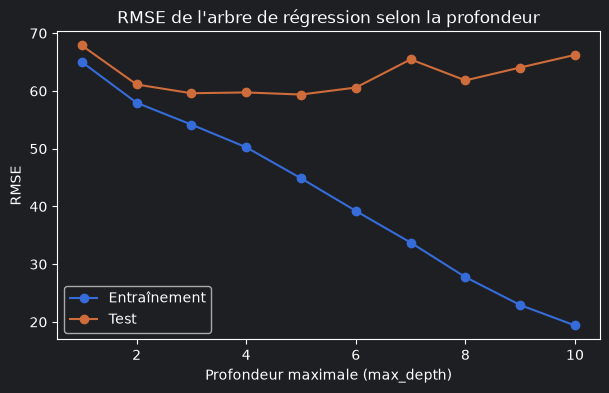

In [16]:
profondeurs = range(1, 11)
rmse_train, rmse_test = [], []
for d in profondeurs:
    arbre = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    rmse_train.append(np.sqrt(mean_squared_error(y_train, arbre.predict(X_train))))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, arbre.predict(X_test))))

plt.figure(figsize=(7, 4))
plt.plot(profondeurs, rmse_train, marker='o', label="Entraînement")
plt.plot(profondeurs, rmse_test, marker='o', label="Test")
plt.title("RMSE de l'arbre de régression selon la profondeur")
plt.xlabel("Profondeur maximale (max_depth)")
plt.ylabel("RMSE")
plt.legend()
plt.show()

La RMSE de test est minimale vers les profondeurs 3 à 5 (≈ 59–60) puis remonte (surapprentissage). Je choisirais **3** : arbre plus simple pour une erreur presque identique.

## Partie E : Interprétation

**Q16.** RMSE et écart-type de `y_test`

In [17]:
rmse_best = resultats.loc[meilleur, 'RMSE']
ecart_type = y_test.std()

print("RMSE du meilleur modèle :", round(rmse_best, 1))
print("Écart-type de y_test    :", round(ecart_type, 1))
print("Réduction de l'erreur   :", round(100 * (1 - rmse_best / ecart_type)), "%")

RMSE du meilleur modèle : 51.0
Écart-type de y_test    : 73.2
Réduction de l'erreur   : 30 %


La RMSE est dans **la même unité que la cible**. Prédire « toujours la moyenne » donnerait une erreur ≈ 73 ; le SVR (≈ 51) réduit l'erreur d'environ **30 %** : gain réel, mais l'erreur reste importante.

**Q17.** R² négatif

Le modèle est **pire que prédire la moyenne**. Cela peut arriver sur le jeu de test avec un modèle mal adapté ou sur-appris (arbre très profond, peu de données).